In [21]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

df = pd.read_csv("../pliki/bank-customers.csv")
df

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,9996,15606229,Obijiaku,771,France,Male,39,5,0.00,2,1,0,96270.64,0
9996,9997,15569892,Johnstone,516,France,Male,35,10,57369.61,1,1,1,101699.77,0
9997,9998,15584532,Liu,709,France,Female,36,7,0.00,1,0,1,42085.58,1
9998,9999,15682355,Sabbatini,772,Germany,Male,42,3,75075.31,2,1,0,92888.52,1


### usuwam kolumnę CustomerId i Surname

In [22]:
df=df.drop(["CustomerId", "Surname", "RowNumber"], axis=1)
df.head()

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [23]:
df.isna().sum()

CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64

In [24]:
df.duplicated().sum()

np.int64(0)

### zmiana Gender na LabelEncoding

In [25]:
from sklearn.preprocessing import LabelEncoder
    
le = LabelEncoder()
df["Gender"] = le.fit_transform(df["Gender"])   
df.head()       

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,619,France,0,42,2,0.00,1,1,1,101348.88,1
1,608,Spain,0,41,1,83807.86,1,0,1,112542.58,0
2,502,France,0,42,8,159660.80,3,1,0,113931.57,1
3,699,France,0,39,1,0.00,2,0,0,93826.63,0
4,850,Spain,0,43,2,125510.82,1,1,1,79084.10,0


## One-Hot dla Geography

In [26]:
df = pd.get_dummies(df, columns=["Geography"], dtype=int)
df.head()

,CreditScore,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Geography_France,Geography_Germany,Geography_Spain
0,619,0,42,2,0.00,1,1,1,101348.88,1,1,0,0
1,608,0,41,1,83807.86,1,0,1,112542.58,0,0,0,1
2,502,0,42,8,159660.80,3,1,0,113931.57,1,1,0,0
3,699,0,39,1,0.00,2,0,0,93826.63,0,1,0,0
4,850,0,43,2,125510.82,1,1,1,79084.10,0,0,0,1


## podział danych

In [27]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=["Exited"])
X = X.select_dtypes(include=[np.number])

y=df["Exited"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [28]:
from sklearn.preprocessing import StandardScaler

standard = StandardScaler()

kolumny_do_skalowania = ["CreditScore", "Tenure", "Age", "Balance", "NumOfProducts", "EstimatedSalary"]

X_train[kolumny_do_skalowania]= standard.fit_transform(X_train[kolumny_do_skalowania])
X_test[kolumny_do_skalowania]= standard.transform(X_test[kolumny_do_skalowania])
X_train.head()

,CreditScore,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Geography_France,Geography_Germany,Geography_Spain
2151,1.058568,1,1.715086,0.684723,-1.226059,-0.910256,1,0,1.042084,1,0,0
8392,0.913626,1,-0.659935,-0.696202,0.413288,-0.910256,1,0,-0.623556,0,1,0
5006,1.079274,0,-0.184931,-1.731895,0.601687,0.808830,1,1,0.308128,0,1,0
4117,-0.929207,1,-0.184931,-0.005739,-1.226059,0.808830,1,0,-0.290199,1,0,0
7182,0.427035,1,0.955079,0.339492,0.548318,0.808830,0,1,0.135042,0,1,0


## trenowanie

In [29]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=100) # , class_weight="balanced", random_state=42
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

## accuracy

In [30]:

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import roc_curve, roc_auc_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

acc = accuracy_score(y_test, y_pred)
acc

0.808

## precision

In [31]:
pre = precision_score(y_test, y_pred, zero_division=0)
pre

0.5891472868217055

## recall

In [32]:
rec = recall_score(y_test, y_pred)
rec

0.18673218673218672

## F1-score

In [33]:
f1 = f1_score(y_test, y_pred)
f1

0.2835820895522388

## AUC

In [34]:
auc = roc_auc_score(y_test, y_prob)
auc

0.7748056222632493

## ROC

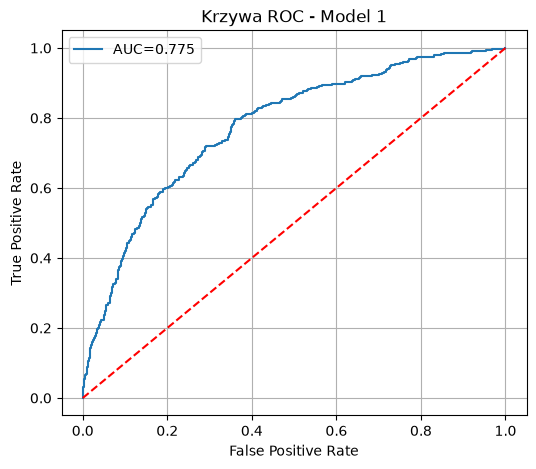

In [35]:
fpr, tpr, _ = roc_curve(y_test, y_prob)

plt.figure(figsize=(6,5))
plt.plot(fpr, tpr, label=f"AUC={auc:.3f}")
plt.plot([0,1],[0,1],'r--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Krzywa ROC - Model 1")
plt.legend()
plt.grid()
plt.show()

## macierz pomyłek

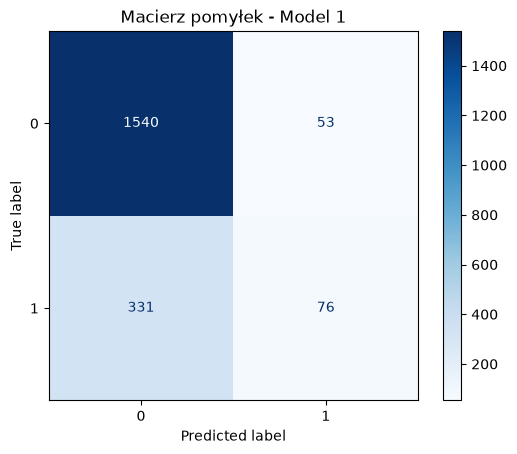

In [36]:
ConfusionMatrixDisplay(confusion_matrix(y_test,y_pred)).plot(cmap="Blues")
plt.title("Macierz pomyłek - Model 1")
plt.show()